# 多资产 HMM 择时 + 等权配置策略

本 notebook 实现一个更清楚的多资产 HMM 择时框架：

- 资产池：沪深300、中证500、中证1000、COMEX黄金、COMEX白银、COMEX铜、布伦特原油；
- HMM 参数：所有资产统一使用 `n_states=6`；
- 预测/持仓周期：`holding_period=40` 个交易日；
- HMM 参数更新频率：默认 `each_rebalance`，即每 40 天调仓时重新训练一次，也可切换为 `quarterly`；
- 组合调仓频率：每 40 个交易日统一调仓；
- 配置方式：对 HMM 预测未来 40 天期望收益为正的资产等权配置；
- 若没有任何资产看多，则全部持有现金。

核心思想是：

```text
按设定频率训练各资产 HMM；
每 40 个交易日统一判断各资产 expected_ret；
expected_ret > 0 的资产进入组合；
进入组合的资产等权。
```


## 1. 依赖、代理与参数


In [51]:
import os
import socket
import warnings
import logging
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from hmmlearn.hmm import GaussianHMM
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", message="Model is not converging")
logging.getLogger("hmmlearn").setLevel(logging.ERROR)

plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25


In [52]:
PROXY_ENV_KEYS = [
    "HTTP_PROXY", "HTTPS_PROXY", "http_proxy", "https_proxy", "ALL_PROXY", "all_proxy",
]

ORIGINAL_PROXY_ENV = {key: os.environ.get(key) for key in PROXY_ENV_KEYS}
ORIGINAL_NO_PROXY = {"NO_PROXY": os.environ.get("NO_PROXY"), "no_proxy": os.environ.get("no_proxy")}


def clear_python_proxy():
    for key in PROXY_ENV_KEYS:
        os.environ.pop(key, None)
    os.environ["NO_PROXY"] = "*"
    os.environ["no_proxy"] = "*"


def restore_python_proxy():
    for key in PROXY_ENV_KEYS:
        value = ORIGINAL_PROXY_ENV.get(key)
        if value is None:
            os.environ.pop(key, None)
        else:
            os.environ[key] = value
    for key, value in ORIGINAL_NO_PROXY.items():
        if value is None:
            os.environ.pop(key, None)
        else:
            os.environ[key] = value


YAHOO_PROXY_URL = "http://127.0.0.1:7897"


def use_yahoo_proxy():
    os.environ["HTTP_PROXY"] = YAHOO_PROXY_URL
    os.environ["HTTPS_PROXY"] = YAHOO_PROXY_URL
    os.environ["http_proxy"] = YAHOO_PROXY_URL
    os.environ["https_proxy"] = YAHOO_PROXY_URL
    os.environ["ALL_PROXY"] = YAHOO_PROXY_URL
    os.environ["all_proxy"] = YAHOO_PROXY_URL
    os.environ.pop("NO_PROXY", None)
    os.environ.pop("no_proxy", None)


print("Using YAHOO_PROXY_URL:", YAHOO_PROXY_URL)


Using YAHOO_PROXY_URL: http://127.0.0.1:7897


In [53]:
ASSETS = [
    "沪深300",
    "中证500",
    "中证1000",
    "COMEX黄金",
    "COMEX白银",
    "COMEX铜",
    "布伦特原油",
]


@dataclass
class HMMEqualWeightConfig:
    start_date: str = "2010-01-01"
    end_date: str = "2026-05-31"
    holding_period: int = 40
    retrain_mode: str = "each_rebalance"  # "each_rebalance" 或 "quarterly"
    n_states: int = 6
    train_window_days: int = 2000
    n_iter: int = 200
    tol: float = 1e-2
    n_restarts: int = 3
    random_state: int = 42
    transaction_fee: float = 0.0


cfg = HMMEqualWeightConfig()
FEATURE_COLS = ["ret_h", "sharpe_h", "vol_ratio", "ret_half"]


## 2. 获取多资产价格数据

A 股指数使用 AkShare 的新浪指数接口；外盘商品使用 Yahoo Finance。

如果 Yahoo Finance 超时，确认 VPN 已开启，并且本地代理端口为 `127.0.0.1:7897`。


In [54]:
import akshare as ak

try:
    import yfinance as yf
except ImportError as exc:
    raise ImportError("请先安装 yfinance：pip install yfinance") from exc


def pick_first_existing_column(df, candidates, required=True):
    for col in candidates:
        if col in df.columns:
            return col
    if required:
        raise KeyError(f"无法找到候选列 {candidates}，当前字段为：{df.columns.tolist()}")
    return None


def normalize_market_data(raw, asset_name, date_candidates, close_candidates, volume_candidates):
    df = raw.copy()
    date_col = pick_first_existing_column(df, date_candidates)
    close_col = pick_first_existing_column(df, close_candidates)
    volume_col = pick_first_existing_column(df, volume_candidates, required=False)

    out = pd.DataFrame()
    out["date"] = pd.to_datetime(df[date_col])
    out["close"] = pd.to_numeric(df[close_col], errors="coerce")
    out["volume"] = pd.to_numeric(df[volume_col], errors="coerce") if volume_col else np.nan
    out["asset"] = asset_name
    out = out.replace([np.inf, -np.inf], np.nan).dropna(subset=["date", "close"])
    out = out.sort_values("date")
    out = out[(out["date"] >= pd.to_datetime(cfg.start_date)) & (out["date"] <= pd.to_datetime(cfg.end_date))]
    return out[["date", "asset", "close", "volume"]]


def load_zh_index(symbol, asset_name):
    clear_python_proxy()
    raw = ak.stock_zh_index_daily(symbol=symbol)
    return normalize_market_data(
        raw,
        asset_name=asset_name,
        date_candidates=["date", "日期"],
        close_candidates=["close", "收盘", "最新价"],
        volume_candidates=["volume", "成交量", "成交额"],
    )


def load_yahoo_future(ticker, asset_name):
    use_yahoo_proxy()
    print(f"{asset_name}: Yahoo ticker={ticker}, HTTPS_PROXY={os.environ.get('HTTPS_PROXY')}")
    raw = yf.download(
        ticker,
        start=cfg.start_date,
        end=(pd.to_datetime(cfg.end_date) + pd.Timedelta(days=1)).strftime("%Y-%m-%d"),
        auto_adjust=False,
        progress=False,
        threads=False,
        timeout=120,
    )
    if raw.empty:
        raise ValueError(f"Yahoo Finance 没有返回数据：{ticker} / {asset_name}")
    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = raw.columns.get_level_values(0)
    raw = raw.reset_index()
    close_col = "Adj Close" if "Adj Close" in raw.columns else "Close"
    return pd.DataFrame(
        {
            "date": pd.to_datetime(raw["Date"]),
            "asset": asset_name,
            "close": pd.to_numeric(raw[close_col], errors="coerce"),
            "volume": pd.to_numeric(raw["Volume"], errors="coerce") if "Volume" in raw.columns else np.nan,
        }
    ).dropna(subset=["date", "close"])[["date", "asset", "close", "volume"]]


zh_index_map = {
    "沪深300": "sh000300",
    "中证500": "sh000905",
    "中证1000": "sh000852",
}

commodity_ticker_map = {
    "COMEX黄金": "GC=F",
    "COMEX白银": "SI=F",
    "COMEX铜": "HG=F",
    "布伦特原油": "BZ=F",
}

zh_data = {}
for asset_name, symbol in zh_index_map.items():
    print(f"Loading {asset_name} {symbol}")
    zh_data[asset_name] = load_zh_index(symbol, asset_name)

commodity_data = {}
for asset_name, ticker in commodity_ticker_map.items():
    print(f"Loading {asset_name} {ticker}")
    commodity_data[asset_name] = load_yahoo_future(ticker, asset_name)

long_df = pd.concat([*zh_data.values(), *commodity_data.values()], ignore_index=True)
long_df = long_df.drop_duplicates(subset=["date", "asset"], keep="last")

price_df = long_df.pivot(index="date", columns="asset", values="close").sort_index().reindex(columns=ASSETS)
volume_df = long_df.pivot(index="date", columns="asset", values="volume").sort_index().reindex(columns=ASSETS)

# 使用全市场日期并前值填充，形成统一组合估值日历。
price_df = price_df.ffill().dropna(how="all")
volume_df = volume_df.reindex(price_df.index).ffill()

display(price_df.head())
display(price_df.tail())
display(price_df.isna().mean().rename("missing_ratio"))
print(price_df.shape)


Loading 沪深300 sh000300
Loading 中证500 sh000905
Loading 中证1000 sh000852
Loading COMEX黄金 GC=F
COMEX黄金: Yahoo ticker=GC=F, HTTPS_PROXY=http://127.0.0.1:7897
Loading COMEX白银 SI=F
COMEX白银: Yahoo ticker=SI=F, HTTPS_PROXY=http://127.0.0.1:7897
Loading COMEX铜 HG=F
COMEX铜: Yahoo ticker=HG=F, HTTPS_PROXY=http://127.0.0.1:7897
Loading 布伦特原油 BZ=F
布伦特原油: Yahoo ticker=BZ=F, HTTPS_PROXY=http://127.0.0.1:7897


asset,沪深300,中证500,中证1000,COMEX黄金,COMEX白银,COMEX铜,布伦特原油
date,,,,,,,
2010-01-04,3535.229,4510.527,NaN,1117.699951,17.440001,3.3880,80.120003
2010-01-05,3564.038,4557.475,NaN,1118.099976,17.781000,3.3960,80.589996
2010-01-06,3541.727,4550.279,NaN,1135.900024,18.163000,3.4775,81.889999
2010-01-07,3471.456,4459.155,NaN,1133.099976,18.333000,3.4115,81.510002
2010-01-08,3480.130,4514.452,NaN,1138.199951,18.458000,3.3880,81.370003


asset,沪深300,中证500,中证1000,COMEX黄金,COMEX白银,COMEX铜,布伦特原油
date,,,,,,,
2026-05-25,4921.597,8703.890,8799.312,4521.000000,75.892998,6.3420,103.540001
2026-05-26,4947.849,8658.619,8687.253,4500.399902,76.305000,6.3610,99.580002
2026-05-27,4908.171,8530.980,8546.514,4447.500000,74.598999,6.3050,94.290001
2026-05-28,4914.213,8563.222,8637.743,4499.299805,75.644997,6.3960,93.709999
2026-05-29,4892.121,8359.560,8408.736,4560.500000,75.615997,6.3595,92.050003


asset
沪深300      0.000000
中证500      0.000000
中证1000     0.292185
COMEX黄金    0.000000
COMEX白银    0.000000
COMEX铜     0.000000
布伦特原油      0.000000
Name: missing_ratio, dtype: float64

(4261, 7)


## 3. 构造 40 日 HMM 观测变量

每个样本代表一个 40 日持仓周期：

- `ret_h`：过去 40 日收益；
- `sharpe_h`：过去 40 日收益 / 波动率；
- `vol_ratio`：过去半周期与全周期成交量均值之比；
- `ret_half`：过去 20 日收益；
- `future_ret`：未来 40 日收益，作为状态收益标签，不作为 HMM 输入。


In [55]:
def build_asset_observations(price_s, volume_s=None, holding_period=40):
    px = price_s.dropna().astype(float)
    h = holding_period
    half_h = max(1, h // 2)

    rows = []
    for i in range(h, len(px) - h, h):
        date = px.index[i]
        next_date = px.index[i + h]
        p0, p1, p2 = px.iloc[i - h], px.iloc[i], px.iloc[i + h]
        p_half = px.iloc[i - half_h]

        ret_h = p1 / p0 - 1
        ret_half = p1 / p_half - 1
        future_ret = p2 / p1 - 1

        daily_ret_window = px.iloc[i - h:i].pct_change().dropna()
        vol = daily_ret_window.std()
        sharpe_h = ret_h / (vol * np.sqrt(h)) if vol and vol > 0 else 0.0

        if volume_s is not None:
            vol_s = volume_s.reindex(px.index).ffill()
            full_vol = vol_s.iloc[i - h:i].mean()
            half_vol = vol_s.iloc[i - half_h:i].mean()
            vol_ratio = half_vol / full_vol if full_vol and full_vol > 0 else 1.0
        else:
            full_std = px.iloc[i - h:i].pct_change().std()
            half_std = px.iloc[i - half_h:i].pct_change().std()
            vol_ratio = half_std / full_std if full_std and full_std > 0 else 1.0

        rows.append(
            {
                "date": date,
                "next_date": next_date,
                "close": p1,
                "ret_h": ret_h,
                "sharpe_h": sharpe_h,
                "vol_ratio": vol_ratio,
                "ret_half": ret_half,
                "future_ret": future_ret,
            }
        )

    obs = pd.DataFrame(rows).replace([np.inf, -np.inf], np.nan).dropna()
    return obs


asset_obs = {}
for asset in ASSETS:
    v = None if volume_df is None else volume_df[asset]
    asset_obs[asset] = build_asset_observations(price_df[asset], volume_s=v, holding_period=cfg.holding_period)

obs_quality = pd.DataFrame(
    {
        asset: [len(obs), obs["date"].min() if len(obs) else pd.NaT, obs["date"].max() if len(obs) else pd.NaT]
        for asset, obs in asset_obs.items()
    },
    index=["n_obs", "start", "end"],
).T
display(obs_quality)


,n_obs,start,end
沪深300,105,2010-03-02 00:00:00,2026-03-06 00:00:00
中证500,105,2010-03-02 00:00:00,2026-03-06 00:00:00
中证1000,74,2014-12-12 00:00:00,2026-03-13 00:00:00
COMEX黄金,105,2010-03-02 00:00:00,2026-03-06 00:00:00
COMEX白银,105,2010-03-02 00:00:00,2026-03-06 00:00:00
COMEX铜,105,2010-03-02 00:00:00,2026-03-06 00:00:00
布伦特原油,105,2010-03-02 00:00:00,2026-03-06 00:00:00


## 4. 按设定频率训练 HMM，并在每 40 日调仓日生成信号

训练频率由 `cfg.retrain_mode` 控制：

- `"each_rebalance"`：每个 40 日调仓日都重新训练一次 HMM；
- `"quarterly"`：每个季度最多训练一次 HMM，季度内复用同一套 `lambda`。

预测信号：

```text
expected_ret = A[current_state] @ state_future_ret_mean
signal = 1{expected_ret > 0}
```


In [56]:
def repair_transition_matrix(transmat):
    transmat = np.asarray(transmat, dtype=float).copy()
    transmat = np.nan_to_num(transmat, nan=0.0, posinf=0.0, neginf=0.0)
    n_states = transmat.shape[0]
    row_sum = transmat.sum(axis=1, keepdims=True)
    zero_rows = row_sum.squeeze() <= 1e-12
    if zero_rows.any():
        transmat[zero_rows, :] = 1.0 / n_states
        row_sum = transmat.sum(axis=1, keepdims=True)
    return transmat / row_sum


def repair_startprob(startprob):
    startprob = np.asarray(startprob, dtype=float).copy()
    startprob = np.nan_to_num(startprob, nan=0.0, posinf=0.0, neginf=0.0)
    if startprob.sum() <= 1e-12:
        startprob[:] = 1.0 / len(startprob)
    else:
        startprob = startprob / startprob.sum()
    return startprob


def fit_best_hmm(X_train, n_states, cfg):
    best_model = None
    best_score = -np.inf
    last_error = None

    for j in range(cfg.n_restarts):
        model = GaussianHMM(
            n_components=n_states,
            covariance_type="diag",
            n_iter=cfg.n_iter,
            tol=cfg.tol,
            random_state=cfg.random_state + j,
            min_covar=1e-4,
            startprob_prior=1.1,
            transmat_prior=1.1,
        )
        try:
            model.fit(X_train)
            model.startprob_ = repair_startprob(model.startprob_)
            model.transmat_ = repair_transition_matrix(model.transmat_)
            score = model.score(X_train)
            if np.isfinite(score) and score > best_score:
                best_model = model
                best_score = score
        except Exception as exc:
            last_error = exc
            continue

    if best_model is None:
        raise RuntimeError(f"HMM fitting failed. last_error={last_error}")
    return best_model


def train_hmm_for_asset_asof(obs, train_end_date, cfg):
    train_periods = max(20, cfg.train_window_days // cfg.holding_period)
    train = obs[obs["date"] < train_end_date].tail(train_periods).copy()
    train = train.replace([np.inf, -np.inf], np.nan).dropna(subset=FEATURE_COLS + ["future_ret"])

    if len(train) < max(30, cfg.n_states * 8):
        return None

    usable_features = [col for col in FEATURE_COLS if train[col].std(ddof=0) > 1e-10]
    if not usable_features:
        return None

    n_states_eff = min(cfg.n_states, max(2, len(train) // 10))

    scaler = StandardScaler()
    X_train = scaler.fit_transform(train[usable_features])
    if (not np.isfinite(X_train).all()) or np.nanstd(X_train) <= 1e-12:
        return None

    model = fit_best_hmm(X_train, n_states_eff, cfg)
    train_states = model.predict(X_train)
    train["state"] = train_states
    state_mean = train.groupby("state")["future_ret"].mean()
    state_mean = state_mean.reindex(range(n_states_eff)).fillna(train["future_ret"].mean())

    return {
        "model": model,
        "scaler": scaler,
        "features": usable_features,
        "state_mean": state_mean,
        "n_states_eff": n_states_eff,
        "train_start": train["date"].min(),
        "train_end": train["date"].max(),
    }


def predict_asset_signal_asof(obs, date, fitted):
    current_hist = obs[obs["date"] <= date]
    if fitted is None or current_hist.empty:
        return np.nan, np.nan, np.nan

    current = current_hist.iloc[-1]
    X_current = fitted["scaler"].transform(current[fitted["features"]].to_frame().T)
    current_state = int(fitted["model"].predict(X_current)[-1])
    transmat = repair_transition_matrix(fitted["model"].transmat_)
    expected_ret = float(transmat[current_state] @ fitted["state_mean"].values)
    signal = int(expected_ret > 0)
    return expected_ret, signal, current_state


In [57]:
# 统一组合调仓日：每 40 个全市场估值日调一次仓。
portfolio_dates = price_df.dropna(how="all").index[::cfg.holding_period]

signal_rows = []
model_cache = {}
train_log = []

if cfg.retrain_mode not in ["each_rebalance", "quarterly"]:
    raise ValueError("cfg.retrain_mode must be 'each_rebalance' or 'quarterly'")


def get_model_cache_key(asset, date, cfg):
    if cfg.retrain_mode == "quarterly":
        return (asset, pd.Timestamp(date).to_period("Q"))
    if cfg.retrain_mode == "each_rebalance":
        return (asset, pd.Timestamp(date))
    raise ValueError(f"Unknown retrain_mode: {cfg.retrain_mode}")


for date in portfolio_dates:
    row = {"date": date}

    for asset in ASSETS:
        cache_key = get_model_cache_key(asset, date, cfg)

        if cache_key not in model_cache:
            try:
                fitted = train_hmm_for_asset_asof(asset_obs[asset], date, cfg)
            except Exception as exc:
                print(f"Training failed: {asset} {date} {type(exc).__name__}: {exc}")
                fitted = None
            model_cache[cache_key] = fitted
            if fitted is not None:
                train_log.append(
                    {
                        "asset": asset,
                        "retrain_mode": cfg.retrain_mode,
                        "cache_key": str(cache_key[1]),
                        "asof_date": date,
                        "train_start": fitted["train_start"],
                        "train_end": fitted["train_end"],
                        "n_states_eff": fitted["n_states_eff"],
                        "n_features_eff": len(fitted["features"]),
                    }
                )

        expected_ret, signal, current_state = predict_asset_signal_asof(asset_obs[asset], date, model_cache[cache_key])
        row[f"{asset}_expected_ret"] = expected_ret
        row[f"{asset}_signal"] = signal
        row[f"{asset}_state"] = current_state

    signal_rows.append(row)

signal_wide = pd.DataFrame(signal_rows).set_index("date").sort_index()
train_log = pd.DataFrame(train_log)

signal_df = signal_wide[[f"{asset}_signal" for asset in ASSETS]].copy()
signal_df.columns = ASSETS
expected_ret_df = signal_wide[[f"{asset}_expected_ret" for asset in ASSETS]].copy()
expected_ret_df.columns = ASSETS

signal_df = signal_df.dropna(how="all")
expected_ret_df = expected_ret_df.reindex(signal_df.index)

display(train_log.tail())
display(signal_df.head())
display(signal_df.mean().rename("signal_ratio"))
print("signal_df shape:", signal_df.shape)


,asset,retrain_mode,cache_key,asof_date,train_start,train_end,n_states_eff,n_features_eff
370,中证1000,each_rebalance,2026-05-01 00:00:00,2026-05-01,2018-08-27,2026-03-13,5,4
371,COMEX黄金,each_rebalance,2026-05-01 00:00:00,2026-05-01,2018-08-20,2026-03-06,5,4
372,COMEX白银,each_rebalance,2026-05-01 00:00:00,2026-05-01,2018-08-20,2026-03-06,5,4
373,COMEX铜,each_rebalance,2026-05-01 00:00:00,2026-05-01,2018-08-20,2026-03-06,5,4
374,布伦特原油,each_rebalance,2026-05-01 00:00:00,2026-05-01,2018-08-20,2026-03-06,5,4


,沪深300,中证500,中证1000,COMEX黄金,COMEX白银,COMEX铜,布伦特原油
date,,,,,,,
2017-07-20,1.0,1.0,NaN,1.0,0.0,0.0,1.0
2017-09-14,1.0,1.0,NaN,1.0,1.0,1.0,1.0
2017-11-09,1.0,1.0,NaN,1.0,1.0,0.0,1.0
2018-01-05,1.0,1.0,NaN,1.0,1.0,0.0,1.0
2018-03-05,1.0,1.0,NaN,1.0,0.0,0.0,1.0


沪深300      0.879310
中证500      0.862069
中证1000     0.592593
COMEX黄金    0.844828
COMEX白银    0.689655
COMEX铜     0.672414
布伦特原油      0.672414
Name: signal_ratio, dtype: float64

signal_df shape: (58, 7)


## 5. 等权组合回测

每个 40 日调仓日：

1. 选出 `signal=1` 的资产；
2. 对这些资产等权；
3. 其他资产权重为 0；
4. 若没有资产看多，则全部现金；
5. 持有到下一个 40 日调仓日。

基准组合为：所有资产始终等权。


In [58]:
def build_equal_weight_from_signal(signal_row):
    active = signal_row[signal_row == 1].index.tolist()
    w = pd.Series(0.0, index=signal_row.index)
    if active:
        w.loc[active] = 1.0 / len(active)
    return w


def max_drawdown(nav):
    nav = pd.Series(nav).dropna()
    dd = nav / nav.cummax() - 1
    return -dd.min()


def summarize_period_strategy(ret, nav, periods_per_year):
    ret = pd.Series(ret).dropna()
    nav = pd.Series(nav).dropna()
    if len(ret) == 0:
        return {}
    ann_ret = nav.iloc[-1] ** (periods_per_year / len(ret)) - 1
    ann_vol = ret.std() * np.sqrt(periods_per_year)
    sharpe = ann_ret / ann_vol if ann_vol > 0 else np.nan
    return {
        "夏普比率": sharpe,
        "年化收益率": ann_ret,
        "总收益率": nav.iloc[-1] - 1,
        "最大回撤": max_drawdown(nav),
        "胜率": (ret > 0).mean(),
    }


bt_rows = []
weight_rows = []

for i in range(len(signal_df) - 1):
    date = signal_df.index[i]
    next_date = signal_df.index[i + 1]

    w = build_equal_weight_from_signal(signal_df.iloc[i].dropna().astype(int))
    asset_ret = price_df.loc[next_date, w.index] / price_df.loc[date, w.index] - 1
    strategy_ret = float(w @ asset_ret.fillna(0.0))

    bench_w = pd.Series(1.0 / len(ASSETS), index=ASSETS)
    bench_ret = float(bench_w @ (price_df.loc[next_date, ASSETS] / price_df.loc[date, ASSETS] - 1).fillna(0.0))

    turnover = 0.0 if not weight_rows else (w - weight_rows[-1]).abs().sum()
    strategy_ret -= cfg.transaction_fee * turnover

    bt_rows.append(
        {
            "date": date,
            "next_date": next_date,
            "strategy_ret": strategy_ret,
            "benchmark_ret": bench_ret,
            "n_active_assets": int((w > 0).sum()),
            "cash_weight": 1 - w.sum(),
            "turnover": turnover,
        }
    )
    weight_rows.append(w)

bt = pd.DataFrame(bt_rows)
bt["strategy_nav"] = (1 + bt["strategy_ret"]).cumprod()
bt["benchmark_nav"] = (1 + bt["benchmark_ret"]).cumprod()
weight_df = pd.DataFrame(weight_rows, index=bt["date"])

periods_per_year = 252 / cfg.holding_period
summary = pd.DataFrame(
    [
        summarize_period_strategy(bt["strategy_ret"], bt["strategy_nav"], periods_per_year),
        summarize_period_strategy(bt["benchmark_ret"], bt["benchmark_nav"], periods_per_year),
    ],
    index=["HMM + 等权", "全资产等权基准"],
)

display(summary)
display(bt.head())
display(weight_df.head())


,夏普比率,年化收益率,总收益率,最大回撤,胜率
HMM + 等权,0.721782,0.112758,1.629162,0.188505,0.614035
全资产等权基准,0.626559,0.107446,1.517756,0.193624,0.578947


,date,next_date,strategy_ret,benchmark_ret,n_active_assets,cash_weight,turnover,strategy_nav,benchmark_nav
0,2017-07-20,2017-09-14,0.076292,0.081129,4,0.000000e+00,0.000000,1.076292,1.081129
1,2017-09-14,2017-11-09,0.030718,0.021638,6,1.110223e-16,0.666667,1.109353,1.104522
2,2017-11-09,2018-01-05,0.017247,0.009258,5,0.000000e+00,0.333333,1.128486,1.114747
3,2018-01-05,2018-03-05,-0.033401,-0.038383,5,0.000000e+00,0.000000,1.090794,1.071960
4,2018-03-05,2018-04-30,0.011747,0.000682,4,0.000000e+00,0.400000,1.103607,1.072691


,沪深300,中证500,COMEX黄金,COMEX白银,COMEX铜,布伦特原油,中证1000
date,,,,,,,
2017-07-20,0.250000,0.250000,0.250000,0.000000,0.000000,0.250000,NaN
2017-09-14,0.166667,0.166667,0.166667,0.166667,0.166667,0.166667,NaN
2017-11-09,0.200000,0.200000,0.200000,0.200000,0.000000,0.200000,NaN
2018-01-05,0.200000,0.200000,0.200000,0.200000,0.000000,0.200000,NaN
2018-03-05,0.250000,0.250000,0.250000,0.000000,0.000000,0.250000,NaN


## 6. 可视化与诊断


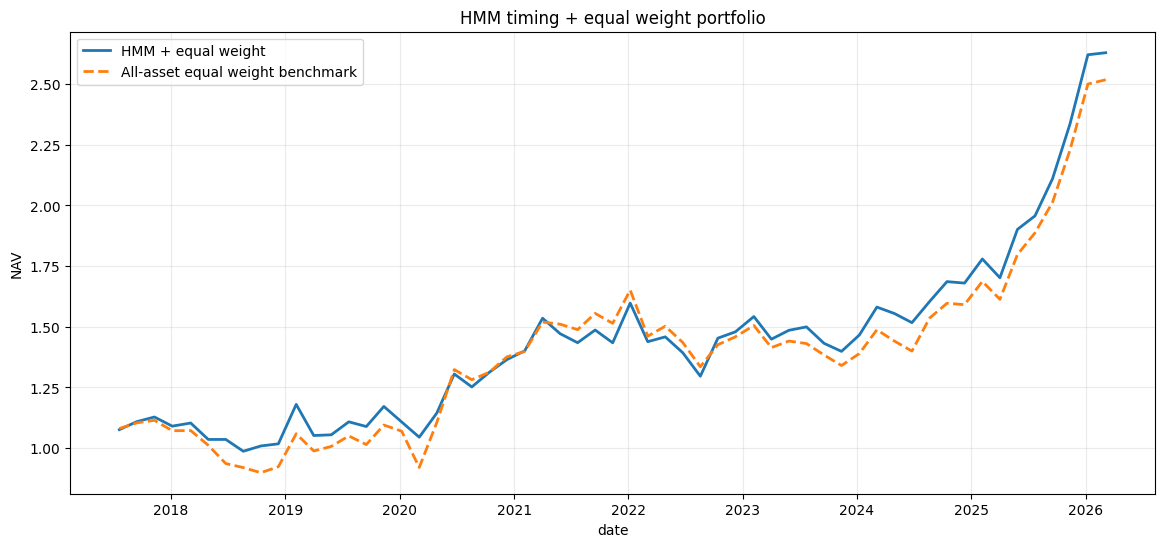

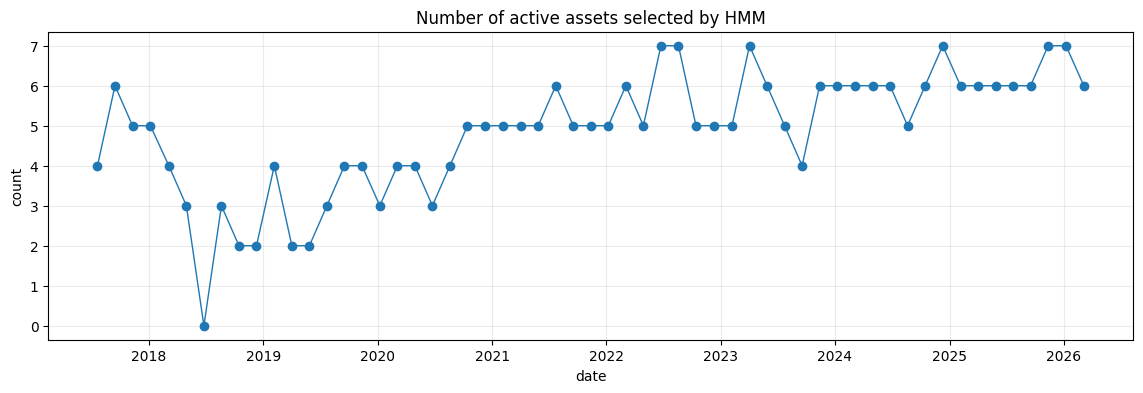

/Users/zhu/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 27818 (\N{CJK UNIFIED IDEOGRAPH-6CAA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/zhu/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 28145 (\N{CJK UNIFIED IDEOGRAPH-6DF1}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/zhu/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 20013 (\N{CJK UNIFIED IDEOGRAPH-4E2D}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/zhu/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 35777 (\N{CJK UNIFIED IDEOGRAPH-8BC1}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/zhu/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 40644

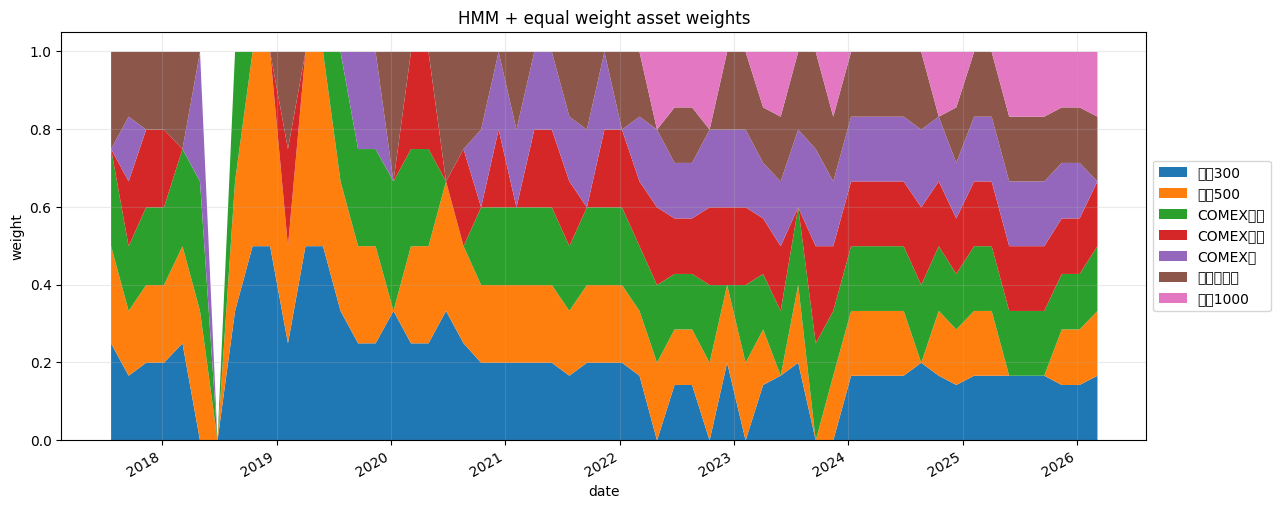

In [59]:
fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(bt["date"], bt["strategy_nav"], label="HMM + equal weight", linewidth=2)
ax.plot(bt["date"], bt["benchmark_nav"], label="All-asset equal weight benchmark", linestyle="--", linewidth=2)
ax.set_title("HMM timing + equal weight portfolio")
ax.set_xlabel("date")
ax.set_ylabel("NAV")
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(bt["date"], bt["n_active_assets"], marker="o", linewidth=1)
ax.set_title("Number of active assets selected by HMM")
ax.set_xlabel("date")
ax.set_ylabel("count")
plt.show()

fig, ax = plt.subplots(figsize=(14, 6))
weight_df.plot.area(ax=ax, linewidth=0)
ax.set_title("HMM + equal weight asset weights")
ax.set_xlabel("date")
ax.set_ylabel("weight")
ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.show()


In [60]:
signal_diagnostics = []
for asset in ASSETS:
    sig = signal_df[asset].dropna()
    aligned_ret = []
    for i in range(len(signal_df) - 1):
        date = signal_df.index[i]
        next_date = signal_df.index[i + 1]
        if pd.notna(signal_df.loc[date, asset]):
            aligned_ret.append(
                {
                    "signal": signal_df.loc[date, asset],
                    "future_ret": price_df.loc[next_date, asset] / price_df.loc[date, asset] - 1,
                }
            )
    tmp = pd.DataFrame(aligned_ret)
    if tmp.empty:
        continue
    signal_diagnostics.append(
        {
            "asset": asset,
            "signal_ratio": sig.mean(),
            "future_ret_when_signal_1": tmp.loc[tmp["signal"] == 1, "future_ret"].mean(),
            "future_ret_when_signal_0": tmp.loc[tmp["signal"] == 0, "future_ret"].mean(),
            "win_rate_when_signal_1": (tmp.loc[tmp["signal"] == 1, "future_ret"] > 0).mean(),
            "win_rate_when_signal_0": (tmp.loc[tmp["signal"] == 0, "future_ret"] > 0).mean(),
        }
    )

signal_diagnostics = pd.DataFrame(signal_diagnostics)
display(signal_diagnostics)


,asset,signal_ratio,future_ret_when_signal_1,future_ret_when_signal_0,win_rate_when_signal_1,win_rate_when_signal_0
0,沪深300,0.879310,0.009643,-0.016983,0.580000,0.428571
1,中证500,0.862069,0.002272,0.052083,0.469388,0.500000
2,中证1000,0.592593,0.029026,0.003979,0.600000,0.545455
3,COMEX黄金,0.844828,0.025135,0.023328,0.625000,0.555556
4,COMEX白银,0.689655,0.030423,0.043720,0.564103,0.444444
5,COMEX铜,0.672414,0.021006,0.010624,0.578947,0.526316
6,布伦特原油,0.672414,0.039038,0.010880,0.578947,0.526316
